In [49]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict, List
from langchain_core.messages.base import BaseMessage
from langchain_core.messages import SystemMessage, ToolMessage, HumanMessage, AIMessage
from langchain_community.chat_models.tongyi import ChatTongyi
from langchain.tools import tool

# 1. 定义工具和模型
model = ChatTongyi(model="qwen3-max")

@tool
def get_weather(location: str) -> str:
    """
    查询天气信息
    :param location: 地理位置
    :return: 天气情况
    """
    return f"今天{location}的温度是 200℃"

@tool
def multiply(a: int, b: int) -> int:
    """
    将`a`和`b`相乘。
    :param a: 第一个整数
    :param b: 第二个整数
    :return: 相乘的结果
    """
    return a * b

# 给 llm 绑定工具列表
tools = [get_weather, multiply]
model_with_tools = model.bind_tools(tools)
tools_by_name = {tool.name: tool for tool in tools}
print("可用工具:", tools_by_name)

可用工具: {'get_weather': StructuredTool(name='get_weather', description='查询天气信息\n:param location: 地理位置\n:return: 天气情况', args_schema=<class 'langchain_core.utils.pydantic.get_weather'>, func=<function get_weather at 0x000001E62EFF6160>), 'multiply': StructuredTool(name='multiply', description='将`a`和`b`相乘。\n:param a: 第一个整数\n:param b: 第二个整数\n:return: 相乘的结果', args_schema=<class 'langchain_core.utils.pydantic.multiply'>, func=<function multiply at 0x000001E62EFF6F20>)}


In [50]:
# 2. 定义状态
class ReActAgentState(TypedDict):
    messages: List[BaseMessage]
    llm_calls: int

In [51]:
# 3. 定义节点
def llm_call(state: ReActAgentState) -> ReActAgentState:
    """LLM决定是否调用工具"""
    msgs = [SystemMessage('你是一个有用的助手。')] + state["messages"]
    ai_message = model_with_tools.invoke(msgs)
    state['messages'] = state["messages"] + [ai_message]
    state['llm_calls'] += 1
    return state

def tool_call(state: ReActAgentState) -> ReActAgentState:
    """执行工具调用"""
    last_message = state["messages"][-1]
    tool_calls = last_message.tool_calls

    for tool_call in tool_calls:
        tool_name = tool_call["name"]
        tool_args = tool_call["args"]
        tool_result = tools_by_name[tool_name].invoke(tool_args)

        state["messages"].append(
            ToolMessage(
                content=str(tool_result),
                tool_call_id=tool_call["id"]
            )
        )

    state['llm_calls'] += 1
    return state

In [52]:
# 4. 构建图
builder = StateGraph(ReActAgentState)
builder.add_node("llm_call", llm_call)
builder.add_node("tool_call", tool_call)

builder.add_edge(START, "llm_call")

# 条件边：判断是否需要调用工具
def router(state: ReActAgentState) -> str:
    last_message = state["messages"][-1]
    if hasattr(last_message, "tool_calls") and last_message.tool_calls:
        return "tool_call"
    return END

builder.add_conditional_edges(
    "llm_call",
    router,
    {
        "tool_call": "tool_call",
        END: END
    }
)

builder.add_edge("tool_call", "llm_call")  # 工具调用后回到LLM

graph = builder.compile()

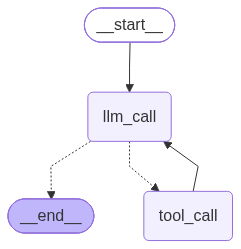

In [53]:
from IPython.display import Image, display
display(Image(graph.get_graph(xray=True).draw_mermaid_png()))

In [54]:
from langchain_core.messages import HumanMessage

print("=" * 50)
print("🤖 ReAct Agent 测试")
print("=" * 50)

# 测试1：乘法
initial_state = {
    "messages": [HumanMessage(content="3乘以4等于多少？")],
    "llm_calls": 0
}

result = graph.invoke(initial_state)
print(result)
print("\n📝 最终结果:")
for msg in result["messages"]:
    msg_type = type(msg).__name__
    # 打印消息内容
    if hasattr(msg, "content") and msg.content:
        print(f"{msg_type}: {msg.content}")
    # 打印 tool_calls
    if hasattr(msg, "tool_calls") and msg.tool_calls:
        for tc in msg.tool_calls:
            print(f"AI  → 调用工具: {tc['name']}({tc['args']})")
print(f"\n📊 LLM调用次数: {result['llm_calls']}")

🤖 ReAct Agent 测试
{'messages': [HumanMessage(content='3乘以4等于多少？', additional_kwargs={}, response_metadata={}), AIMessage(content='', additional_kwargs={'tool_calls': [{'function': {'arguments': '{"a": 3, "b": 4}', 'name': 'multiply'}, 'id': 'call_b525b46b413649b8b783f5fc', 'index': 0, 'type': 'function'}]}, response_metadata={'model_name': 'qwen3-max', 'finish_reason': 'tool_calls', 'request_id': '6d43a07d-9af6-9902-98b9-7fd0e685ff15', 'token_usage': {'input_tokens': 373, 'output_tokens': 29, 'prompt_tokens_details': {'cached_tokens': 0}, 'total_tokens': 402}}, id='lc_run--019f98f8-118a-7902-bb8a-9b7399b954b7-0', tool_calls=[{'name': 'multiply', 'args': {'a': 3, 'b': 4}, 'id': 'call_b525b46b413649b8b783f5fc', 'type': 'tool_call'}], invalid_tool_calls=[]), ToolMessage(content='12', tool_call_id='call_b525b46b413649b8b783f5fc'), AIMessage(content='3乘以4等于12。', additional_kwargs={}, response_metadata={'model_name': 'qwen3-max', 'finish_reason': 'stop', 'request_id': '06f19bfc-c6d6-9e53-8bc5